# Humanos frente a bots: clustering de sesiones a partir de logs de servidor web

*Trabajo final de Aprendizaje Automático I* · Celia Sáenz Villalta

## Introducción y motivación

Una parte creciente del tráfico de cualquier web la generan programas: buscadores, herramientas SEO, servicios de monitorización, escáneres de vulnerabilidades y, cada vez más, *crawlers* y agentes de inteligencia artificial. Muchos se identifican en la cabecera *user-agent* (GPTBot, ClaudeBot, Googlebot…). Los scrapers, los bots maliciosos y los agentes que manejan un navegador real, en cambio, envían el *user-agent* de un navegador corriente, y ese campo no basta para detectarlos.

La motivación es personal. En mi trabajo en Arsys desarrollo automatizaciones que navegan por webs como si fueran usuarios, así que este trabajo mira el problema desde el lado contrario: ¿puede distinguirse el tráfico humano del automatizado solo por su comportamiento?

La mayoría de los trabajos publicados sobre detección de bots usan aprendizaje supervisado. Aquí se sigue un enfoque no supervisado en tres pasos:

1. Agrupar las sesiones de navegación por su comportamiento, sin ninguna etiqueta, con k-means y DBSCAN.
2. Validar los grupos *a posteriori* con una etiqueta aproximada derivada del *user-agent*, que no se usa como variable.
3. Reunir el resultado en una función `analizar_log(ruta)` que estima qué parte del tráfico de un log cualquiera es humana y qué parte automatizada.

El estudio se limita a las sesiones de ordenador (Windows, macOS, Linux) y descarta las de navegadores de sistemas operativos móviles (Android, iOS…). Las herramientas de automatización de navegadores (Selenium, Playwright, Puppeteer) y los agentes de IA que navegan por la web se ejecutan casi siempre en un navegador de escritorio, y los bots que se camuflan suelen copiar un *user-agent* de Chrome en Windows. El tráfico móvil, además, trae patrones propios que no encajan del todo ni en la navegación humana ni en los bots, como las peticiones automáticas de iconos de los iPhone o las imágenes que descargan las aplicaciones Android. Y si no se mezclan pantallas táctiles y de escritorio, el comportamiento humano es más homogéneo. Los bots declarados se conservan siempre, digan usar el sistema que digan, porque hacen falta para la validación.

## Datos

| | |
|---|---|
| Fuente | Zaker (2019), *Online Shopping Store – Web Server Logs*, Harvard Dataverse / Kaggle |
| Contenido | Log de acceso de la tienda online zanbil.ir (Irán), en formato *combined* de Apache |
| Tamaño | 3,5 GB (se usan las primeras 24 horas, unos 2,3 millones de líneas) |
| Licencia | CC0 |
| Etiquetas | Ninguna |

En Harvard Dataverse el fichero tiene acceso restringido, así que se ha usado la copia pública de Kaggle (Elias Dabbas, licencia CC0), que contiene el mismo `access.log`. Las IPs se sustituyen por un *hash* al cargarlas. Conviene tener presente al interpretar los resultados que el log es anterior a la expansión de los *crawlers* y agentes de IA.

In [6]:
import re, gzip, zipfile, io, glob, os, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 80)
sns.set_theme(style='whitegrid')

SEMILLA = 0
N_INIT = 50   # inicializaciones de k-means, para que la solución no dependa del azar de la inicialización
RUTA_2019 = 'datos/zaker2019_kaggle.zip'                          # copia de Kaggle del log de Zaker
os.makedirs('figuras', exist_ok=True)
os.makedirs('modelos', exist_ok=True)

## 1. Carga y parseo del log

El log sigue el formato *combined* de Apache:

```
IP - - [fecha] "MÉTODO URL PROTOCOLO" código tamaño "referer" "user-agent"
```

La función `cargar_log` lee ficheros de texto, `.gz` o `.zip` sin descomprimirlos en disco. Admite un patrón con comodines para leer varios ficheros rotados y permite limitar la lectura a un número de líneas o a una ventana de tiempo, algo necesario con los 3,5 GB del log de 2019. De ese log se toman las primeras 24 horas completas, para recoger el ciclo diario entero (noche, mañana y tarde) y no una sola franja horaria. Las líneas que no encajan con la expresión regular o cuya fecha no se puede interpretar se descartan y se cuentan.

In [7]:
PATRON_COMBINED = re.compile(
    r'^(?P<ip>\S+) \S+ \S+ \[(?P<fecha>[^\]]+)\] '
    r'"(?P<metodo>[A-Z]+) (?P<url>\S+)(?: \S+)?" '
    r'(?P<codigo>\d{3}) (?P<tamano>\d+|-) '
    r'"(?P<referer>[^"]*)" "(?P<user_agent>[^"]*)"'
)

def _abrir(ruta):
    """Abre un log en modo texto, tanto si es plano como si está comprimido (.gz o .zip)."""
    if ruta.endswith('.gz'):
        return gzip.open(ruta, 'rt', encoding='utf-8', errors='replace')
    if ruta.endswith('.zip'):
        z = zipfile.ZipFile(ruta)
        miembro = max(z.infolist(), key=lambda i: i.file_size)   # el log es el fichero más grande
        return io.TextIOWrapper(z.open(miembro), encoding='utf-8', errors='replace')
    return open(ruta, encoding='utf-8', errors='replace')

def anonimizar(ip):
    return hashlib.md5(ip.encode()).hexdigest()[:10]

FORMATO_FECHA = '%d/%b/%Y:%H:%M:%S %z'

def cargar_log(ruta, n_lineas=None, horas=None, anonimizar_ip=True, verbose=True):
    """Lee un log en formato combined y devuelve un DataFrame con una petición por fila.

    n_lineas: máximo de líneas a leer. horas: lee solo las primeras `horas` horas desde la primera petición.
    """
    rutas = sorted(glob.glob(ruta)) if isinstance(ruta, str) else list(ruta)
    filas, leidas, malas, limite, parar = [], 0, 0, None, False
    for r in rutas:
        with _abrir(r) as f:
            for linea in f:
                if n_lineas is not None and leidas >= n_lineas:
                    break
                leidas += 1
                m = PATRON_COMBINED.match(linea)
                if not m:
                    malas += 1
                    continue
                filas.append(m.groupdict())
                if horas is not None and (limite is None or len(filas) % 10_000 == 0):
                    try:
                        t = pd.to_datetime(filas[-1]['fecha'], format=FORMATO_FECHA)
                    except ValueError:
                        continue
                    if limite is None:
                        limite = t + pd.Timedelta(hours=horas)
                    elif t > limite:          # se comprueba cada 10 000 líneas; luego se recorta exacto
                        parar = True
                        break
        if parar:
            break
    df = pd.DataFrame(filas)
    df['fecha'] = pd.to_datetime(df['fecha'], format=FORMATO_FECHA, errors='coerce')
    malas += df['fecha'].isna().sum()
    df = df.dropna(subset=['fecha'])
    if limite is not None:
        df = df[df['fecha'] < limite]
    df['codigo'] = df['codigo'].astype(int)
    df['tamano'] = pd.to_numeric(df['tamano'], errors='coerce').fillna(0).astype(int)
    if anonimizar_ip:
        df['ip'] = df['ip'].map(anonimizar)
    if verbose:
        print(f'{len(rutas)} fichero(s), {leidas:,} líneas leídas, {malas:,} descartadas '
              f'({malas / max(leidas, 1):.4%})')
    return df.reset_index(drop=True)

In [8]:
log19 = cargar_log(RUTA_2019, horas=24)
print(f'Peticiones en las primeras 24 horas: {len(log19):,}')
print('Intervalo temporal:', log19['fecha'].min(), '→', log19['fecha'].max())
log19.head(3)

1 fichero(s), 2,350,047 líneas leídas, 47 descartadas (0.0020%)
Peticiones en las primeras 24 horas: 2,341,896
Intervalo temporal: 2019-01-22 03:56:14+03:30 → 2019-01-23 03:56:13+03:30


,ip,fecha,metodo,url,codigo,tamano,referer,user_agent
0,53b52b5858,2019-01-22 03:56:14+03:30,GET,"/filter/27|13%20%D9%85%DA%AF%D8%A7%D9%BE%DB%8C%DA%A9%D8%B3%D9%84,27|%DA%A9%D...",200,30577,-,Mozilla/5.0 (compatible; AhrefsBot/6.1; +http://ahrefs.com/robot/)
1,451128fcd3,2019-01-22 03:56:16+03:30,GET,/image/60844/productModel/200x200,200,5667,https://www.zanbil.ir/m/filter/b113,Mozilla/5.0 (Linux; Android 6.0; ALE-L21 Build/HuaweiALE-L21) AppleWebKit/53...
2,451128fcd3,2019-01-22 03:56:16+03:30,GET,/image/61474/productModel/200x200,200,5379,https://www.zanbil.ir/m/filter/b113,Mozilla/5.0 (Linux; Android 6.0; ALE-L21 Build/HuaweiALE-L21) AppleWebKit/53...


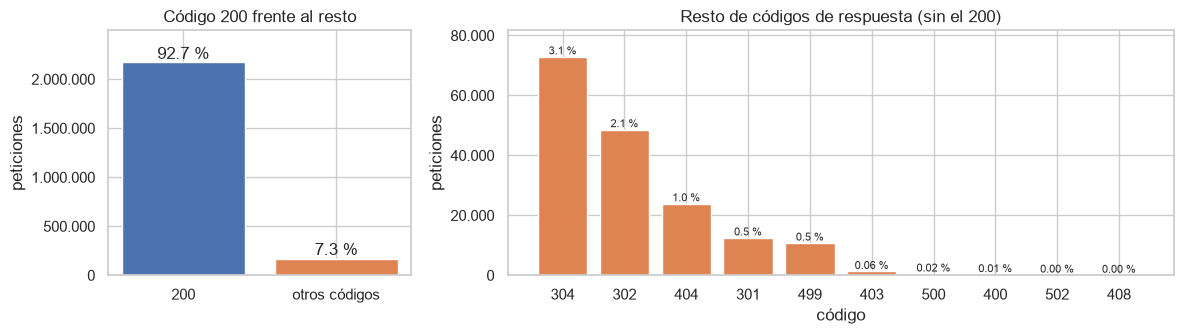

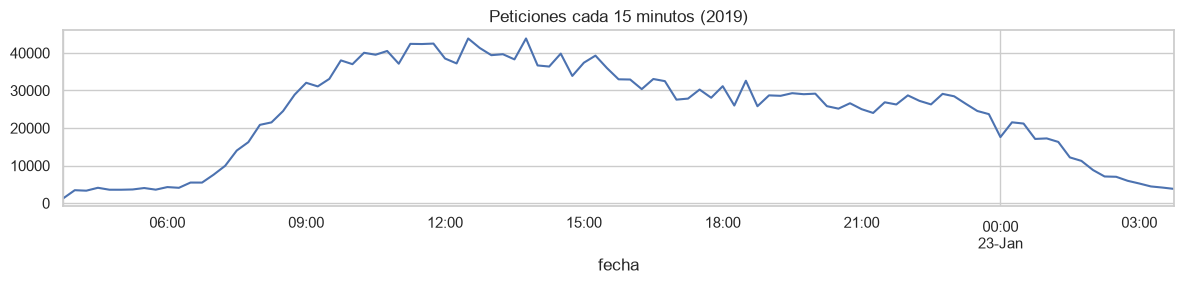

In [9]:
codigos = log19['codigo'].value_counts()
otros = codigos.drop(200)
pct = lambda n: f'{100 * n / len(log19):.1f} %' if n / len(log19) >= 0.001 else f'{100 * n / len(log19):.2f} %'
miles = plt.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.'))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={'width_ratios': [1, 2.2]})
# Izquierda: 200 frente al resto
partes = pd.Series({'200': codigos[200], 'otros códigos': otros.sum()})
barras = ax[0].bar(partes.index, partes.values, color=['#4C72B0', '#DD8452'])
ax[0].bar_label(barras, labels=[pct(n) for n in partes.values])
ax[0].set(title='Código 200 frente al resto', ylabel='peticiones', ylim=(0, partes.max() * 1.15))
ax[0].yaxis.set_major_formatter(miles)
# Derecha: desglose de los demás códigos
top = otros.head(10)
barras = ax[1].bar(top.index.astype(str), top.values, color='#DD8452')
ax[1].bar_label(barras, labels=[pct(n) for n in top.values], fontsize=8)
ax[1].set(title='Resto de códigos de respuesta (sin el 200)', xlabel='código', ylabel='peticiones',
          ylim=(0, top.max() * 1.12))
ax[1].yaxis.set_major_formatter(miles)
plt.tight_layout(); plt.savefig('figuras/codigos_respuesta_2019.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(12, 3))
log19.set_index('fecha').resample('15min').size().plot(ax=ax, title='Peticiones cada 15 minutos (2019)')
plt.tight_layout(); plt.show()

**// Comentario:** La expresión regular interpreta casi todo el log: de las 2 350 047 líneas leídas solo se descartan 47 (0,0020 %), así que el formato *combined* se lee bien. Tras recortar a la ventana exacta de 24 horas (del 22/01/2019 a las 03:56 al 23/01/2019 a las 03:56) quedan 2 341 896 peticiones. El 92,7 % de ellas obtienen un código 200. El 7,3 % restante se reparte sobre todo entre el 304 (3,1 %, recursos que el navegador ya tenía en caché), el 302 (2,1 %, redirecciones), el 404 (1,0 %, recursos inexistentes), el 301 (0,5 %) y el 499 (0,5 %, conexiones que el cliente cierra antes de recibir la respuesta). Con tan pocos errores, en este log apenas hay crawlers probando URLs inexistentes.

## 2. Sesiones y variables de comportamiento

Cada fila del log es una petición individual, con la IP, la fecha, la URL, el código de respuesta, el *referer* y el *user-agent*. Agrupar esas filas directamente no serviría para distinguir bots de humanos, por tres motivos:

- Una petición aislada no revela quién la hace. Un `GET /product/123` es idéntico venga de una persona o de un programa. Lo que delata a un bot es el conjunto de su actividad: el ritmo al que pide páginas, la regularidad de los intervalos, si descarga las hojas de estilo e imágenes que un navegador carga automáticamente, si llega siguiendo enlaces o si consulta `robots.txt`.
- Las columnas originales no se prestan a un algoritmo basado en distancias. Casi todas son texto (URL, *referer*, *user-agent*), y las numéricas (código de respuesta, tamaño) describen la respuesta del servidor más que el comportamiento del cliente.
- La única columna que identifica al cliente de forma explícita, el *user-agent*, se reserva para la validación y no puede usarse como variable.

Por eso la unidad de análisis pasa a ser la sesión de usuario, que se resume en un conjunto de variables numéricas sobre su comportamiento (ingeniería de características). De paso se reduce el volumen de datos: los 2,3 millones de peticiones del día se convierten en unas 80 000 sesiones.

Una sesión es el conjunto de peticiones con la misma IP y el mismo *user-agent*, y se corta cuando pasan más de 30 minutos sin actividad, el criterio habitual en analítica web. Para cada sesión se calculan estas variables:

| Variable | Descripción |
|---|---|
| `n_peticiones` | Número de peticiones de la sesión. |
| `duracion_s` | Segundos transcurridos entre la primera y la última petición de la sesión. |
| `pet_por_min` | Peticiones por minuto: número de peticiones dividido entre la duración (con un mínimo de un segundo). |
| `media_dt` | Tiempo medio, en segundos, entre dos peticiones consecutivas. |
| `cv_dt` | Coeficiente de variación del tiempo entre peticiones (desviación típica dividida entre la media). Vale 0 cuando todos los intervalos son iguales. |
| `pct_estaticos` | Proporción de peticiones a recursos estáticos: hojas de estilo, scripts, imágenes y fuentes. |
| `pct_4xx` | Proporción de peticiones que reciben un error del cliente (códigos 400 a 499). |
| `pidio_robots` | Vale 1 si la sesión pidió `robots.txt` o el *sitemap*, y 0 si no. |
| `pct_sin_referer` | Proporción de peticiones que llegan sin cabecera *referer*. |
| `pct_head` | Proporción de peticiones hechas con el método HEAD. |
| `pct_urls_distintas` | Número de URLs distintas dividido entre el número de peticiones. |

In [10]:
EXT_ESTATICOS = re.compile(
    r'(?:\.(?:css|js|png|jpe?g|gif|svg|ico|webp|woff2?|ttf|eot|map|mp4|webm)(?:\?|$))'
    r'|^/(?:images?|static|styles?|scripts|js|css|plugins|fonts|assets)/', re.I)

CANDIDATAS = ['n_peticiones', 'duracion_s', 'pet_por_min', 'media_dt', 'cv_dt', 'pct_estaticos',
              'pct_4xx', 'pidio_robots', 'pct_sin_referer', 'pct_head', 'pct_urls_distintas']
VARIABLES_LOG = ['n_peticiones', 'duracion_s', 'pet_por_min', 'media_dt', 'cv_dt']   # muy asimétricas

def crear_sesiones(df, inactividad_min=30):
    """Asigna a cada petición un identificador de sesión (misma IP y user-agent, corte por inactividad)."""
    df = df.sort_values(['ip', 'user_agent', 'fecha']).reset_index(drop=True)
    cambio = (df['ip'] != df['ip'].shift()) | (df['user_agent'] != df['user_agent'].shift())
    hueco = df['fecha'].diff().dt.total_seconds()
    nueva = cambio | (hueco > inactividad_min * 60)
    df['sesion'] = nueva.cumsum()
    df['dt'] = hueco.where(~nueva)        # segundos desde la petición anterior de la misma sesión
    return df

def calcular_variables(df):
    """Una fila por sesión con las variables de comportamiento."""
    d = df.assign(estatico=df['url'].str.contains(EXT_ESTATICOS),
                  error4xx=df['codigo'].between(400, 499),
                  robots=df['url'].str.contains(r'robots\.txt|sitemap', case=False),
                  sin_referer=df['referer'].isin(['-', '']),
                  head=df['metodo'].eq('HEAD'))
    g = d.groupby('sesion')
    ses = pd.DataFrame({
        'ip': g['ip'].first(),
        'user_agent': g['user_agent'].first(),
        'inicio': g['fecha'].min(),
        'n_peticiones': g.size(),
        'duracion_s': (g['fecha'].max() - g['fecha'].min()).dt.total_seconds(),
        'media_dt': g['dt'].mean(),
        'std_dt': g['dt'].std(ddof=0),
        'pct_estaticos': g['estatico'].mean(),
        'pct_4xx': g['error4xx'].mean(),
        'pidio_robots': g['robots'].max().astype(int),
        'pct_sin_referer': g['sin_referer'].mean(),
        'pct_head': g['head'].mean(),
        'pct_urls_distintas': g['url'].nunique() / g.size(),
    })
    ses['pet_por_min'] = ses['n_peticiones'] / np.maximum(ses['duracion_s'], 1) * 60
    ses['cv_dt'] = (ses['std_dt'] / ses['media_dt'].replace(0, np.nan)).fillna(0)
    return ses

In [11]:
log19 = crear_sesiones(log19)
ses19 = calcular_variables(log19)
una = ses19['n_peticiones'] == 1
print(f'Sesiones: {len(ses19):,}')
print(f'Sesiones de una sola petición: {una.mean():.1%} de las sesiones, '
      f'{ses19.loc[una, "n_peticiones"].sum() / ses19["n_peticiones"].sum():.1%} de las peticiones')
ses19[CANDIDATAS].describe().T.round(2)

Sesiones: 80,423
Sesiones de una sola petición: 39.2% de las sesiones, 1.3% de las peticiones


,count,mean,std,min,25%,50%,75%,max
n_peticiones,80423.0,29.12,305.16,1.00,1.00,2.00,20.0,62973.0
duracion_s,80423.0,267.84,1793.36,0.00,0.00,5.00,117.0,86390.0
pet_por_min,80423.0,73.53,152.94,0.05,11.32,60.00,60.0,5070.0
media_dt,48886.0,91.49,252.47,0.00,0.97,3.50,28.0,1799.0
cv_dt,80423.0,1.39,2.17,0.00,0.00,0.00,2.3,19.4
pct_estaticos,80423.0,0.70,0.41,0.00,0.40,0.94,1.0,1.0
pct_4xx,80423.0,0.03,0.14,0.00,0.00,0.00,0.0,1.0
pidio_robots,80423.0,0.00,0.05,0.00,0.00,0.00,0.0,1.0
pct_sin_referer,80423.0,0.42,0.49,0.00,0.00,0.01,1.0,1.0
pct_head,80423.0,0.00,0.03,0.00,0.00,0.00,0.0,1.0


En una sesión de una sola petición no están definidas las variables temporales (duración, ritmo, tiempo entre peticiones). Ponerles un 0 crearía un grupo artificial definido solo por ese valor, así que estas sesiones se excluyen del clustering. Son una fracción apreciable de las sesiones, pero apenas alrededor del 1 % de las peticiones, de modo que se pierde poco. La herramienta final las cuenta aparte como «1 petición (sin clasificar)».

## 3. Etiqueta aproximada a partir del *user-agent* (solo para validar)

La columna `tipo_ua` clasifica cada sesión según lo que declara su *user-agent*:

- `bot_declarado`: contiene `bot`, `crawler`, `spider`, `uptime`, `monitor`, `curl`, `python`, `wget`, `scan`… o está vacío.
- `navegador`: el resto.

El log es de 2019, anterior a los *crawlers* de inteligencia artificial, así que no se crea una categoría específica para ellos. Los *crawlers* que se identifican (Googlebot, bingbot, AhrefsBot, CCBot…) son de buscadores, herramientas SEO o archivos de la web, y todos cuentan como bots declarados.

La etiqueta es imperfecta, porque un *user-agent* de navegador no garantiza que detrás haya una persona. Por eso sirve para interpretar los grupos y no se usa para entrenar.

In [12]:
BOTS = re.compile(
    r'bot|crawl|spider|slurp|uptime|monitor|curl|python|wget|scan|go-http|java/|libwww|okhttp|'
    r'axios|node-fetch|headless|phantom|httpclient|facebookexternalhit|zgrab|masscan|nmap|nikto|'
    r'sqlmap|feed|fetch|preview|^-?$', re.I)

def etiqueta_ua(ua):
    if BOTS.search(ua):
        return 'bot_declarado'
    return 'navegador'

ses19['tipo_ua'] = ses19['user_agent'].map(etiqueta_ua)
pd.DataFrame({'todas': ses19['tipo_ua'].value_counts(),
              '≥ 2 peticiones': ses19.loc[~una, 'tipo_ua'].value_counts()})

,todas,≥ 2 peticiones
tipo_ua,,
navegador,71439,44355
bot_declarado,8984,4531


In [13]:
ses19.loc[ses19['tipo_ua'] != 'navegador', 'user_agent'].str[:90].value_counts().head(10)

user_agent
Mozilla/5.0 (compatible; AhrefsBot/6.1; +http://ahrefs.com/robot/)                            6224
Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/534+ (KHTML, like Gecko) BingPreview/1.0b     1159
Mozilla/5.0 (Linux; Android 6.0.1; Nexus 5X Build/MMB29P) AppleWebKit/537.36 (KHTML, like      181
Mozilla/5.0 (compatible; bingbot/2.0; +http://www.bing.com/bingbot.htm)                        150
Mozilla/5.0 (compatible; Googlebot/2.1; +http://www.google.com/bot.html)                       145
Mozilla/5.0 (compatible; Baiduspider/2.0; +http://www.baidu.com/search/spider.html)            130
Googlebot-Image/1.0                                                                            129
okhttp/2.5.0                                                                                   113
Mozilla/5.0 (iPhone; CPU iPhone OS 7_0 like Mac OS X) AppleWebKit/537.51.1 (KHTML, like Ge      90
Mozilla/5.0 (compatible; Parsijoobot; +http://www.parsijoo.ir/bot.html; crawler@parsijoo.i      88

### 3.1 Restricción al tráfico de ordenador

Se marcan como móviles las sesiones de navegador cuyo *user-agent* menciona un sistema o un cliente móvil (Android, iPhone, iPad, iOS, `Mobile`, Dalvik, CFNetwork, Windows Phone…) y se excluyen del resto del análisis. Las sesiones de bots declarados se mantienen aunque su *user-agent* imite un móvil.

In [14]:
MOVIL = re.compile(r'Android|iPhone|iPad|iPod|\biOS\b|Mobile|Dalvik|CFNetwork|NetworkingExtension|'
                   r'Windows Phone|BlackBerry|Opera Mini|webOS|KaiOS|SamsungBrowser', re.I)

def es_movil(ses):
    """Sesiones de navegador con user-agent móvil (los bots declarados nunca se marcan)."""
    return ses['user_agent'].str.contains(MOVIL) & ses['tipo_ua'].eq('navegador')

def tipo_cliente(ua):
    if etiqueta_ua(ua) != 'navegador':
        return 'bot declarado'
    return 'móvil' if MOVIL.search(ua) else 'ordenador'

Antes de excluir el tráfico móvil, el siguiente gráfico muestra cómo se reparten las peticiones a lo largo de las 24 horas entre navegadores de ordenador, navegadores móviles y bots declarados (hora local de Irán, UTC+03:30).

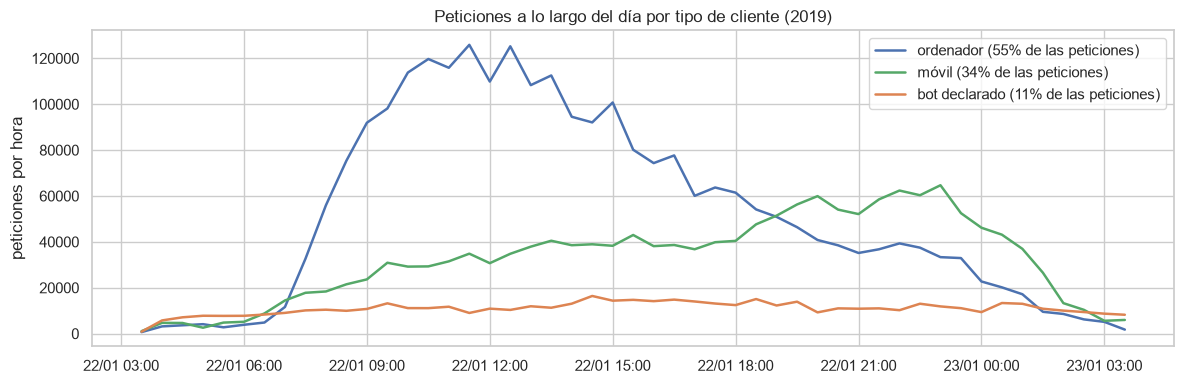

user_agent,bot declarado,móvil,ordenador
franja (hora local),,,
00–06 h,26.5,48.6,24.9
06–12 h,9.9,21.5,68.7
12–18 h,9.3,26.6,64.1
18–24 h,10.8,50.4,38.7


In [15]:
import matplotlib.dates as mdates
uas = log19['user_agent'].unique()
cliente = log19['user_agent'].map(dict(zip(uas, map(tipo_cliente, uas))))
por_hora = (log19.assign(cliente=cliente).set_index('fecha')
            .groupby('cliente').resample('30min').size().unstack(0).fillna(0) * 2)   # ritmo en peticiones/hora

fig, ax = plt.subplots(figsize=(12, 4))
for c, color in [('ordenador', '#4C72B0'), ('móvil', '#55A868'), ('bot declarado', '#DD8452')]:
    ax.plot(por_hora.index, por_hora[c], label=f'{c} ({cliente.eq(c).mean():.0%} de las peticiones)',
            color=color, lw=1.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:%M', tz=por_hora.index.tz))
ax.set(ylabel='peticiones por hora', title='Peticiones a lo largo del día por tipo de cliente (2019)')
ax.legend(); plt.tight_layout(); plt.savefig('figuras/peticiones_dia_2019.png', dpi=150); plt.show()

# Reparto porcentual por franja horaria
franja = pd.cut(log19['fecha'].dt.hour, bins=[0, 6, 12, 18, 24], right=False,
                labels=['00–06 h', '06–12 h', '12–18 h', '18–24 h'])
pd.crosstab(franja, cliente, normalize='index').mul(100).round(1).rename_axis('franja (hora local)')

**// Comentario:** Cada tipo de tráfico sigue un patrón horario distinto. El de ordenador (55 % de las peticiones) se concentra en horario laboral, con un máximo de unas 125 000 peticiones por hora entre las 11:00 y las 13:00, y baja por la tarde. El móvil (34 %) crece de forma sostenida durante el día, supera al de ordenador hacia las 18:30 y llega a su máximo en torno a las 23:00. Los bots declarados (11 %) mantienen un ritmo casi constante de 10 000 a 15 000 peticiones por hora de día y de noche, de modo que entre las 00:00 y las 06:00 son el 26,5 % de las peticiones, frente a alrededor del 10 % durante el día. Esa curva plana ya es una señal de comportamiento automatizado. El gráfico justifica además usar 24 horas completas, porque con una franja parcial el reparto del tráfico habría salido sesgado.

In [16]:
movil19 = es_movil(ses19)
display(pd.crosstab(ses19['tipo_ua'], movil19.rename('móvil'), margins=True))
print(f'Sesiones móviles excluidas: {movil19.sum():,} ({movil19.mean():.1%} de las sesiones, '
      f'{ses19.loc[movil19, "n_peticiones"].sum() / ses19["n_peticiones"].sum():.1%} de las peticiones)')
ses19 = ses19[~movil19].copy()
una = ses19['n_peticiones'] == 1
print(f'Sesiones de ordenador: {len(ses19):,}; con ≥ 2 peticiones: {(~una).sum():,}')
ses19.loc[ses19['tipo_ua'] == 'navegador', 'user_agent'].str[:80].value_counts().head(6)

móvil,False,True,All
tipo_ua,,,
bot_declarado,8984,0,8984
navegador,15600,55839,71439
All,24584,55839,80423


Sesiones móviles excluidas: 55,839 (69.4% de las sesiones, 33.9% de las peticiones)
Sesiones de ordenador: 24,584; con ≥ 2 peticiones: 16,507


user_agent
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko)    2733
Mozilla/5.0 (Windows NT 6.1; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko)     2254
Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/71.0.    1895
Mozilla/5.0 (Windows NT 6.1; rv:64.0) Gecko/20100101 Firefox/64.0                   1379
Mozilla/5.0 (Windows NT 6.1; Win64; x64; rv:64.0) Gecko/20100101 Firefox/64.0       1053
Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:64.0) Gecko/20100101 Firefox/64.0       920
Name: count, dtype: int64

**// Comentario:** El tráfico móvil pesa mucho en esta tienda. Se excluyen 55 839 sesiones, el 69,4 % del total y el 78 % de las de navegador, aunque solo suman el 33,9 % de las peticiones porque las sesiones móviles son más cortas. Quedan 24 584 sesiones de ordenador, 16 507 de ellas con al menos dos peticiones, una muestra amplia para el clustering. Los *user-agents* que quedan son Chrome y Firefox en distintas versiones de Windows, el perfil que suelen imitar los bots camuflados. La contrapartida es que un bot que se haga pasar por un móvil queda fuera del estudio, una limitación que se asume con el ámbito elegido.

## 4. Clustering

### 4.1 Selección de variables (reducción de la dimensionalidad)

Las variables de recuento y de tiempo son muy asimétricas (hay sesiones de miles de peticiones), así que se transforman con $\log(1+x)$ y después se estandarizan con `StandardScaler`. Antes de agrupar se comprueba si alguna de las once candidatas es redundante. Es razonable sospecharlo, porque cuatro de ellas están ligadas por definición: la duración es aproximadamente el número de peticiones por el tiempo medio entre ellas, y el ritmo es aproximadamente la inversa de ese tiempo medio. Para comprobarlo se calculan:

- la matriz de correlaciones entre las variables transformadas;
- el $R^2$ de una regresión lineal que explica cada variable temporal a partir de las otras tres;
- la varianza acumulada de las componentes principales.

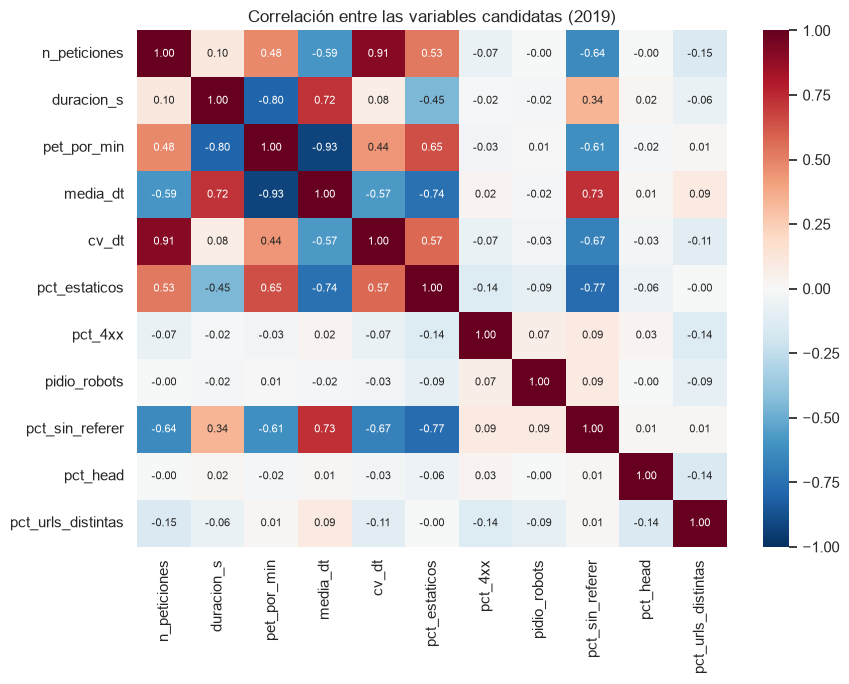

,R² explicado por las otras tres
n_peticiones,0.984
duracion_s,0.991
pet_por_min,0.978
media_dt,0.979


,1,2,3,4,5,6,7,8,9,10,11
varianza acumulada,0.412,0.566,0.681,0.773,0.858,0.928,0.967,0.987,0.995,1.0,1.0


In [18]:
from sklearn.linear_model import LinearRegression

def matriz(ses, variables=None):
    """Matriz de variables transformadas con log(1+x) cuando procede (sin estandarizar)."""
    variables = VARIABLES if variables is None else variables
    X = ses[variables].copy()
    logv = [v for v in variables if v in VARIABLES_LOG]
    X[logv] = np.log1p(X[logv])
    return X

datos19 = ses19[ses19['n_peticiones'] > 1].copy()
Xc = matriz(datos19, CANDIDATAS)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(Xc.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax,
            annot_kws={'size': 8})
ax.set_title('Correlación entre las variables candidatas (2019)')
plt.tight_layout(); plt.savefig('figuras/correlaciones_2019.png', dpi=150); plt.show()

temporales = ['n_peticiones', 'duracion_s', 'pet_por_min', 'media_dt']
r2 = {}
for v in temporales:
    otras = [o for o in temporales if o != v]
    r2[v] = LinearRegression().fit(Xc[otras], Xc[v]).score(Xc[otras], Xc[v])
display(pd.Series(r2, name='R² explicado por las otras tres').round(3).to_frame())

var_acum = np.cumsum(PCA(random_state=SEMILLA).fit(StandardScaler().fit_transform(Xc)).explained_variance_ratio_)
pd.Series(var_acum, index=range(1, len(CANDIDATAS) + 1), name='varianza acumulada').round(3).to_frame().T

**// Comentario:** La redundancia se confirma. Cada una de las cuatro variables temporales queda explicada casi por completo por las otras tres, con un $R^2$ entre 0,978 (`pet_por_min`) y 0,991 (`duracion_s`), y la correlación entre el ritmo y el tiempo medio entre peticiones es de −0,93. Las componentes principales apuntan en la misma dirección: siete recogen ya el 96,7 % de la varianza y las tres últimas aportan solo un 1,3 %, de modo que las once variables contienen en la práctica unas ocho o nueve dimensiones de información. Hay también una correlación de 0,91 entre `cv_dt` y `n_peticiones`, debida en parte a la definición del coeficiente de variación, que con pocas peticiones solo puede tomar valores pequeños.

Se eliminan `duracion_s` y `pet_por_min`, que se reconstruyen casi exactamente a partir de `n_peticiones` y `media_dt`, así que no se pierde información. `cv_dt` se mantiene pese a su correlación con `n_peticiones`: esa correlación viene en parte de la propia definición del coeficiente de variación, y es la única variable que mide la regularidad de la sesión, uno de los rasgos más característicos de un programa. Tampoco se eliminan `pct_head` ni `pidio_robots`, que casi siempre valen 0 pero son las únicas que identifican la monitorización y los *crawlers* que leen `robots.txt`. Se seleccionan variables en vez de usar las componentes principales como entrada para poder leer los perfiles de los clústeres en unidades originales. Las dos variables eliminadas se siguen calculando como descriptivas para los ejemplos.

### 4.2 Visualización con PCA

Con las nueve variables seleccionadas se proyectan las sesiones en dos dimensiones con PCA, para hacerse una primera idea de la estructura.

Variables del modelo (9): ['n_peticiones', 'media_dt', 'cv_dt', 'pct_estaticos', 'pct_4xx', 'pidio_robots', 'pct_sin_referer', 'pct_head', 'pct_urls_distintas']
Sesiones para clustering: (16507, 9)
Varianza explicada por las 2 componentes: [0.412 0.142] → 0.555


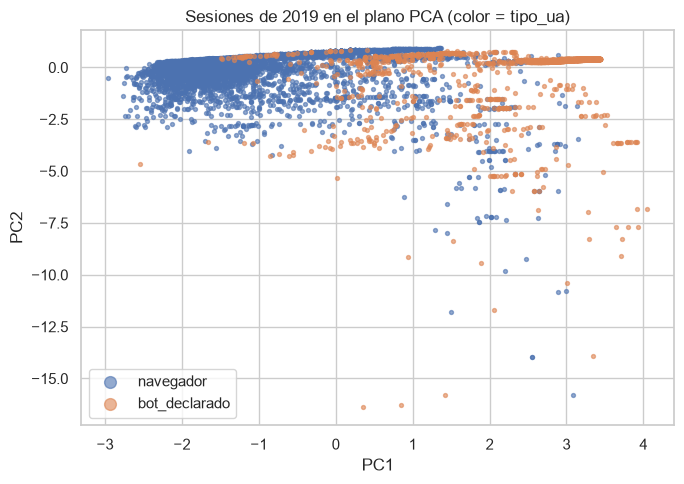

In [19]:
VARIABLES = [v for v in CANDIDATAS if v not in ('duracion_s', 'pet_por_min')]
print(f'Variables del modelo ({len(VARIABLES)}):', VARIABLES)

escalador19 = StandardScaler().fit(matriz(datos19))
Z19 = escalador19.transform(matriz(datos19))
print('Sesiones para clustering:', Z19.shape)

pca19 = PCA(n_components=2, random_state=SEMILLA).fit(Z19)
P19 = pca19.transform(Z19)
print('Varianza explicada por las 2 componentes:', pca19.explained_variance_ratio_.round(3),
      '→', pca19.explained_variance_ratio_.sum().round(3))

rng = np.random.RandomState(SEMILLA)
muestra = rng.choice(len(Z19), size=min(10_000, len(Z19)), replace=False)   # para silhouette y gráficos

fig, ax = plt.subplots(figsize=(7, 5))
tipos = datos19['tipo_ua'].values
for tipo, color in [('navegador', '#4C72B0'), ('bot_declarado', '#DD8452')]:
    m = muestra[tipos[muestra] == tipo]
    ax.scatter(P19[m, 0], P19[m, 1], s=8, alpha=0.6, color=color, label=tipo)
ax.legend(markerscale=3)
ax.set(xlabel='PC1', ylabel='PC2', title='Sesiones de 2019 en el plano PCA (color = tipo_ua)')
plt.tight_layout(); plt.savefig('figuras/pca_tipo_ua_2019.png', dpi=150); plt.show()

**// Comentario:** Las dos primeras componentes principales explican el 55,5 % de la varianza (0,412 y 0,142), suficiente para una visualización orientativa. Las sesiones con *user-agent* de bot se concentran en una región compacta del extremo derecho del plano y las de navegador forman una nube densa a la izquierda. Entre ambas zonas hay sesiones de los dos tipos mezcladas, y algunas de navegador quedan junto a los bots, lo que hace pensar en bots que se presentan como navegadores.

### 4.3 k-means: elección de k

Se ajusta k-means para $k = 2, \dots, 10$ y se calculan la inercia (método del codo), el coeficiente de silhouette (sobre una muestra de 10 000 sesiones, por coste), el índice de Calinski-Harabasz (mayor es mejor) y el de Davies-Bouldin (menor es mejor).

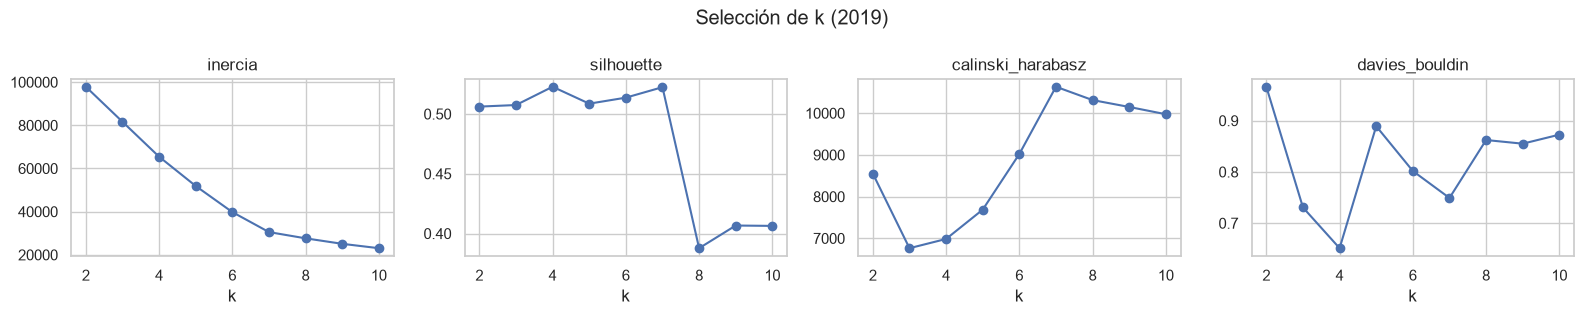

,inercia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,97863.442,0.506,8550.666,0.966
3,81641.525,0.507,6764.174,0.731
4,65450.467,0.523,6985.473,0.651
5,51882.058,0.509,7687.768,0.889
6,39790.149,0.514,9021.636,0.802
7,30528.312,0.522,10632.606,0.749
8,27636.821,0.388,10313.173,0.862
9,25091.122,0.407,10148.242,0.855
10,23064.043,0.406,9973.953,0.873


In [20]:
def evaluar_kmeans(Z, ks, muestra):
    filas = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEMILLA).fit(Z)
        filas.append({'k': k, 'inercia': km.inertia_,
                      'silhouette': silhouette_score(Z[muestra], km.labels_[muestra]),
                      'calinski_harabasz': calinski_harabasz_score(Z, km.labels_),
                      'davies_bouldin': davies_bouldin_score(Z, km.labels_)})
    return pd.DataFrame(filas).set_index('k')

def dibujar_metricas(met, titulo, fichero=None):
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
    for a, col in zip(ax, met.columns):
        a.plot(met.index, met[col], 'o-'); a.set_title(col); a.set_xlabel('k')
    fig.suptitle(titulo); plt.tight_layout()
    if fichero: plt.savefig(fichero, dpi=150)
    plt.show()

met19 = evaluar_kmeans(Z19, range(2, 11), muestra)
dibujar_metricas(met19, 'Selección de k (2019)', 'figuras/seleccion_k_2019.png')
met19.round(3)

**// Comentario:** Entre k = 3 y k = 7 el silhouette apenas cambia (entre 0,507 y 0,523) y a partir de k = 8 cae bruscamente (0,388), así que el número razonable de grupos está en ese intervalo. Dentro de él, k = 4 tiene el mejor Davies-Bouldin (0,651) y empata en silhouette con k = 7 (0,523 frente a 0,522), que es el segundo mejor en Davies-Bouldin (0,749). Para decidir entre los dos se examinan a continuación los grupos que produce cada uno. k-means se ejecuta siempre con 50 inicializaciones (`n_init = 50`), para que la solución no dependa del azar de la inicialización.

In [21]:
K19 = 7
km19 = KMeans(n_clusters=K19, n_init=N_INIT, random_state=SEMILLA).fit(Z19)
datos19['cluster'] = km19.labels_

### 4.4 Perfil de cada clúster

Para interpretar los grupos se muestra la mediana de cada variable por clúster. El color del mapa de calor indica a cuántas desviaciones típicas está la media del clúster de la media global (en el espacio estandarizado), y el número es la mediana en unidades originales.

Los grupos se nombran aplicando en orden unas reglas sencillas sobre las medianas del perfil, de forma que el etiquetado sea reproducible y pueda reutilizarse con otros logs. Cada nombre tiene asociado un tipo: humano, automatizado o ambiguo.

| Orden | Condición sobre la mediana del clúster | Nombre | Tipo |
|---|---|---|---|
| 1 | `pct_head` > 0,5 | monitorización (HEAD) | automatizado |
| 2 | `pidio_robots` > 0,5 | crawler (pide robots.txt) | automatizado |
| 3 | `pct_4xx` > 0,5 | errores 4xx / sondeo | automatizado |
| 4 | `media_dt` > 300 s y sin *referer* | crawler lento y regular | automatizado |
| 5 | `pct_sin_referer` < 0,5 | navegación humana (≥ 10 peticiones) o visita corta | humano |
| 6 | `pct_estaticos` ≥ 0,5 | recursos sueltos sin *referer* | ambiguo |
| 7 | resto | acceso directo sin *referer* ni estáticos | ambiguo |

El *referer* se evalúa a propósito antes que la proporción de estáticos. Un humano que vuelve a una web tiene los CSS e imágenes en la caché del navegador y no los pide de nuevo, así que la falta de estáticos no basta para señalar un bot, mientras que llegar siguiendo enlaces internos sí es un rasgo claramente humano. Los grupos sin *referer* que no encajan en ningún patrón automatizado claro se dejan como ambiguos.

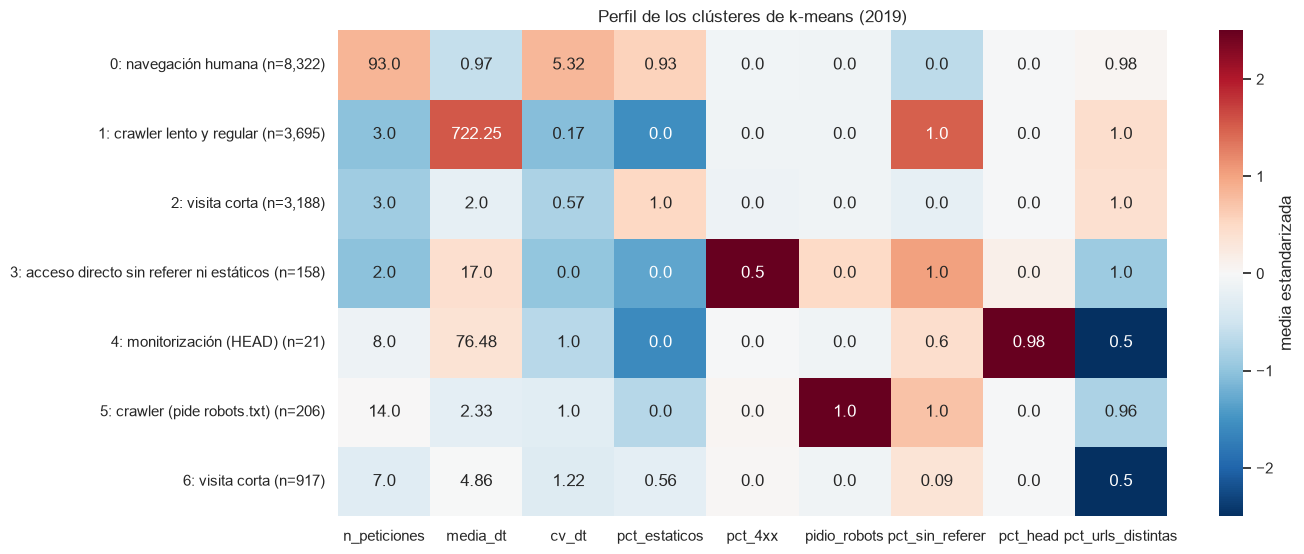

,nombre,tipo,sesiones,peticiones
0,navegación humana,humano,8322,1199602
1,crawler lento y regular,automatizado,3695,18357
2,visita corta,humano,3188,19156
3,acceso directo sin referer ni estáticos,ambiguo,158,1397
4,monitorización (HEAD),automatizado,21,3141
5,crawler (pide robots.txt),automatizado,206,67977
6,visita corta,humano,917,230555


In [22]:
def perfil(datos, etiquetas):
    return datos[VARIABLES].groupby(etiquetas).median().assign(
        sesiones=pd.Series(etiquetas).value_counts().sort_index().values,
        peticiones=datos.groupby(etiquetas)['n_peticiones'].sum().values)

def nombrar(p):
    """Nombre y tipo de un clúster a partir de las medianas de su perfil."""
    if p['pct_head'] > 0.5:          return 'monitorización (HEAD)', 'automatizado'
    if p['pidio_robots'] > 0.5:      return 'crawler (pide robots.txt)', 'automatizado'
    if p['pct_4xx'] > 0.5:           return 'errores 4xx / sondeo', 'automatizado'
    if p['media_dt'] > 300 and p['pct_sin_referer'] >= 0.5:
        return 'crawler lento y regular', 'automatizado'
    if p['pct_sin_referer'] < 0.5:
        return ('navegación humana' if p['n_peticiones'] >= 10 else 'visita corta'), 'humano'
    if p['pct_estaticos'] >= 0.5:    return 'recursos sueltos sin referer', 'ambiguo'
    return 'acceso directo sin referer ni estáticos', 'ambiguo'

def nombrar_clusters(datos, etiquetas):
    p = perfil(datos, etiquetas)
    nombres = {c: nombrar(fila) for c, fila in p.iterrows()}
    return p.assign(nombre=[nombres[c][0] for c in p.index], tipo=[nombres[c][1] for c in p.index]), nombres

def mapa_perfil(Z, etiquetas, p, titulo, fichero=None):
    medias_z = pd.DataFrame(Z, columns=VARIABLES).groupby(etiquetas).mean()
    filas = [f'{c}: {p.loc[c, "nombre"]} (n={p.loc[c, "sesiones"]:,})' for c in medias_z.index]
    fig, ax = plt.subplots(figsize=(14, 0.6 * len(filas) + 1.5))
    sns.heatmap(medias_z.clip(-2.5, 2.5), annot=p[VARIABLES].round(2).values, fmt='', cmap='RdBu_r',
                center=0, yticklabels=filas, ax=ax, cbar_kws={'label': 'media estandarizada'})
    ax.set_title(titulo); plt.tight_layout()
    if fichero: plt.savefig(fichero, dpi=150)
    plt.show()

perfil19, nombres19 = nombrar_clusters(datos19, datos19['cluster'].values)
datos19['grupo'] = datos19['cluster'].map(lambda c: nombres19[c][0])
datos19['tipo'] = datos19['cluster'].map(lambda c: nombres19[c][1])
mapa_perfil(Z19, datos19['cluster'].values, perfil19, 'Perfil de los clústeres de k-means (2019)',
            'figuras/perfil_clusters_2019.png')
perfil19[['nombre', 'tipo', 'sesiones', 'peticiones']]

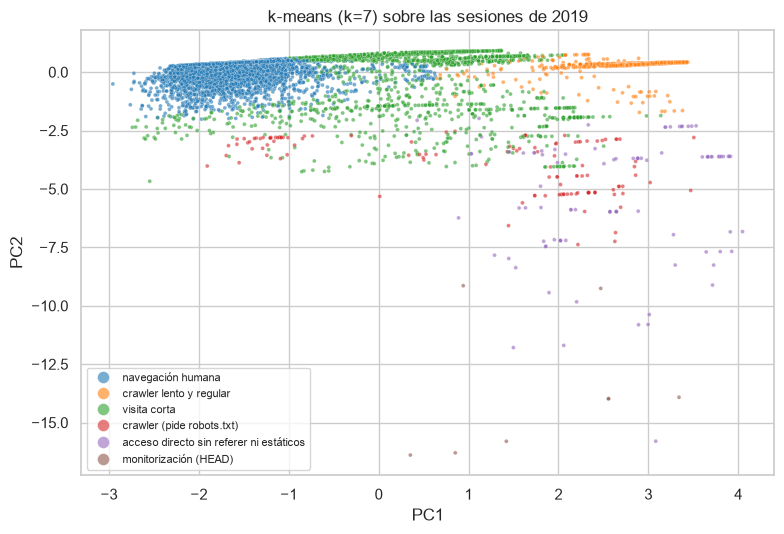

In [23]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(x=P19[muestra, 0], y=P19[muestra, 1], hue=datos19['grupo'].values[muestra],
                s=8, alpha=0.6, ax=ax, palette='tab10')
ax.set(xlabel='PC1', ylabel='PC2', title=f'k-means (k={K19}) sobre las sesiones de 2019')
ax.legend(markerscale=3, fontsize=8, loc='best')
plt.tight_layout(); plt.savefig('figuras/pca_kmeans_2019.png', dpi=150); plt.show()

In [24]:
# URLs más pedidas en los grupos automatizados y ambiguos
for g in perfil19.loc[perfil19['tipo'] != 'humano', 'nombre'].unique():
    ids = datos19.index[datos19['grupo'] == g]
    print(f'--- {g}')
    print(log19.loc[log19['sesion'].isin(ids), 'url'].str[:60].value_counts().head(6).to_string(), '\n')

--- crawler lento y regular
url
/filter/b481%2Cb226%2Cb570%2Cb598%2Cstexists%2Cb880%2Cb270%2    137
/filter/b481%2Cb226%2Cb570%2Cb80%2Cb270%2Cb903%2Cb883%2Cb152     80
/filter/b481%2Cb874%2Cb32%2Cb226%2Cb136%2Cb570%2Cb598%2Cb180     66
/filter/b546%2Cb734%2Cb19%2Cb256%2Cb724%2Cb877%2Cb573%2Cb523     46
/filter/b1,b103,b105,b109,b111,b113,b135,b144,b176,b186,b221     45
/filter/b481%2Cb874%2Cb226%2Cb570%2Cb598%2Cstexists%2Cb880%2     32 

--- acceso directo sin referer ni estáticos
url
/                                                              266
/image/%7B%7BbasketItem.id%7D%7D?type=productModel&wh=50x50     40
/ads.txt                                                        38
/plugins/ckeditor-3.6.2.2/js/ckeditor/ckeditor.js               18
/robots.txt                                                     16
/image/2/productTypeMenu                                        13 

--- monitorización (HEAD)
url
/                                                               3086
/produc

**// Comentario:** Los siete clústeres corresponden a seis tipos de comportamiento, porque las visitas cortas salen divididas en dos subgrupos. La navegación humana (8 322 sesiones) reúne el 77,9 % de las peticiones agrupadas: una mediana de 93 peticiones por sesión con menos de un segundo entre ellas, un coeficiente de variación alto (5,32), *referer* siempre presente y un 93 % de recursos estáticos. En el extremo opuesto, el crawler lento y regular (3 695 sesiones) pide una página cada 722 s de mediana, con un coeficiente de variación de solo 0,17 y sin estáticos, y recorre sistemáticamente las páginas de filtros de la tienda (`/filter/…`). Los grupos de robots.txt (206 sesiones) y de monitorización HEAD (21, que casi siempre piden la portada) son pequeños pero tienen un perfil muy marcado. El de acceso directo sin *referer* ni estáticos (158) se distingue por un 50 % de errores 4xx. Las dos visitas cortas (3 188 y 917 sesiones) cargan recursos estáticos y llegan con *referer*, como una consulta humana breve.

En la selección de k, k = 4 empataba con k = 7 en silhouette y tenía el mejor Davies-Bouldin, así que antes de descartarlo se examinan los grupos que produce.

In [25]:
km4 = KMeans(n_clusters=4, n_init=N_INIT, random_state=SEMILLA).fit(Z19)
perfil4, nombres4 = nombrar_clusters(datos19, km4.labels_)
columnas = ['nombre', 'tipo', 'sesiones', 'n_peticiones', 'media_dt', 'cv_dt', 'pct_estaticos', 'pct_sin_referer']
print('k = 4'); display(perfil4[columnas].round(2))
print(f'k = {K19}'); display(perfil19[columnas].round(2))

k = 4


,nombre,tipo,sesiones,n_peticiones,media_dt,cv_dt,pct_estaticos,pct_sin_referer
0,navegación humana,humano,10897,74.0,1.05,4.33,0.93,0.00
1,crawler lento y regular,automatizado,5370,3.0,515.50,0.04,0.00,1.00
2,monitorización (HEAD),automatizado,23,7.0,76.48,1.00,0.00,0.57
3,crawler (pide robots.txt),automatizado,217,10.0,2.59,1.00,0.00,1.00


k = 7


,nombre,tipo,sesiones,n_peticiones,media_dt,cv_dt,pct_estaticos,pct_sin_referer
0,navegación humana,humano,8322,93.0,0.97,5.32,0.93,0.00
1,crawler lento y regular,automatizado,3695,3.0,722.25,0.17,0.00,1.00
2,visita corta,humano,3188,3.0,2.00,0.57,1.00,0.00
3,acceso directo sin referer ni estáticos,ambiguo,158,2.0,17.00,0.00,0.00,1.00
4,monitorización (HEAD),automatizado,21,8.0,76.48,1.00,0.00,0.60
5,crawler (pide robots.txt),automatizado,206,14.0,2.33,1.00,0.00,1.00
6,visita corta,humano,917,7.0,4.86,1.22,0.56,0.09


**// Comentario:** Con k = 4 se mantienen los grupos pequeños de robots.txt y de monitorización, pero desaparecen las visitas cortas. Sus sesiones se reparten entre la navegación humana, que pasa de 8 322 a 10 897 sesiones, y el crawler lento, que pasa de 3 695 a 5 370. El perfil del crawler lento lo delata: su tiempo mediano entre peticiones baja de 722 s a 515 s, porque ha absorbido sesiones breves que no tienen ese ritmo pausado y regular. El mejor Davies-Bouldin de k = 4 sale, por tanto, de formar grupos más compactos que mezclan comportamientos distintos. Se elige k = 7, que separa todos los tipos de sesión con un silhouette prácticamente igual.

### 4.5 DBSCAN

DBSCAN no necesita fijar el número de grupos y marca como ruido los puntos que no pertenecen a ninguna zona densa. Aquí eso resulta útil, porque las sesiones raras podrían ser bots poco frecuentes o agresivos. Siguiendo la heurística habitual se toma `min_samples` $\approx 2 \cdot d = 18$, y `eps` se elige a partir del gráfico de distancias al k-ésimo vecino, calculadas sobre todas las sesiones.

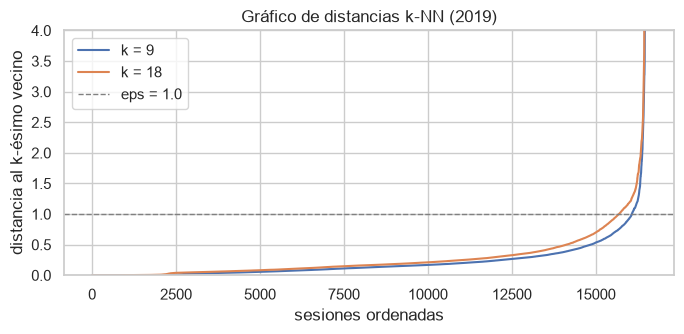

In [26]:
EPS19 = 1.0   # elegido con el gráfico de distancias k-NN
vecinos = NearestNeighbors(n_neighbors=18).fit(Z19)
dist, _ = vecinos.kneighbors(Z19)
fig, ax = plt.subplots(figsize=(7, 3.5))
for k in [9, 18]:
    ax.plot(np.sort(dist[:, k - 1]), label=f'k = {k}')
ax.axhline(EPS19, color='grey', ls='--', lw=1, label=f'eps = {EPS19}')
ax.set(ylim=(0, 4), xlabel='sesiones ordenadas', ylabel='distancia al k-ésimo vecino',
       title='Gráfico de distancias k-NN (2019)')
ax.legend(); plt.tight_layout(); plt.show()

In [27]:
filas = []
for eps in [0.5, 0.8, 1.0, 1.5]:
    for ms in [9, 18]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z19)
        filas.append({'eps': eps, 'min_samples': ms, 'clusters': lab.max() + 1,
                      'pct_ruido': (lab == -1).mean(),
                      'ARI_tipo_ua': adjusted_rand_score(datos19['tipo_ua'], lab),
                      'ARI_kmeans': adjusted_rand_score(datos19['cluster'], lab)})
pd.DataFrame(filas).round(3)

,eps,min_samples,clusters,pct_ruido,ARI_tipo_ua,ARI_kmeans
0,0.5,9,39,0.070,0.662,0.616
1,0.5,18,15,0.107,0.636,0.604
2,0.8,9,28,0.026,0.727,0.592
3,0.8,18,18,0.047,0.711,0.601
4,1.0,9,16,0.016,0.738,0.523
5,1.0,18,15,0.025,0.750,0.550
6,1.5,9,6,0.009,0.020,0.052
7,1.5,18,7,0.011,0.021,0.053


In [28]:
db19 = DBSCAN(eps=EPS19, min_samples=18).fit_predict(Z19)
datos19['dbscan'] = db19
print(f'Clústeres: {db19.max() + 1}, ruido: {(db19 == -1).mean():.1%}')

# ¿Cómo se reparten los grupos de k-means entre los clústeres de DBSCAN?
pd.crosstab(datos19['grupo'], datos19['dbscan'])

Clústeres: 15, ruido: 2.5%


dbscan,-1,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
grupo,,,,,,,,,,,,,,,,
acceso directo sin referer ni estáticos,100,0,0,0,0,0,38,0,20,0,0,0,0,0,0,0
crawler (pide robots.txt),84,0,0,69,0,35,0,0,0,0,0,0,0,0,18,0
crawler lento y regular,20,3600,17,0,43,0,0,0,0,0,0,0,14,0,0,1
monitorización (HEAD),21,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
navegación humana,28,24,8240,0,0,0,0,0,0,0,0,0,30,0,0,0
visita corta,154,603,2977,0,0,0,0,111,0,72,24,95,0,28,0,41


In [29]:
ruido = datos19['dbscan'] == -1
comp = pd.DataFrame({'ruido': datos19.loc[ruido, 'tipo_ua'].value_counts(normalize=True),
                     'resto': datos19.loc[~ruido, 'tipo_ua'].value_counts(normalize=True)}).round(3)
display(comp)
display(pd.DataFrame({'ruido (mediana)': datos19.loc[ruido, VARIABLES].median(),
                      'resto (mediana)': datos19.loc[~ruido, VARIABLES].median()}).round(2).T)
datos19.loc[ruido, 'user_agent'].str[:80].value_counts().head(8)

,ruido,resto
tipo_ua,,
navegador,0.56,0.73
bot_declarado,0.44,0.27


,n_peticiones,media_dt,cv_dt,pct_estaticos,pct_4xx,pidio_robots,pct_sin_referer,pct_head,pct_urls_distintas
ruido (mediana),6.0,15.00,1.03,0.00,0.0,0.0,1.00,0.0,0.67
resto (mediana),29.0,2.42,2.40,0.91,0.0,0.0,0.01,0.0,1.00


user_agent
Mozilla/5.0 (Windows NT 6.1; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko)     27
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko)    22
Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/71.0.    17
Mozilla/5.0 (Macintosh; Intel Mac OS X 10_10_1) AppleWebKit/600.1.25 (KHTML, lik    17
Mozilla/5.0 (compatible; MJ12bot/v1.4.8; http://mj12bot.com/)                       16
Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:64.0) Gecko/20100101 Firefox/64.0      14
Mozilla/5.0 (compatible; DotBot/1.1; http://www.opensiteexplorer.org/dotbot, hel    14
Googlebot-Image/1.0                                                                 12
Name: count, dtype: int64

**// Comentario:** En el gráfico de distancias al 18.º vecino la curva empieza a subir con rapidez en torno a 1,0. Con `eps = 1.0` y `min_samples = 18` se obtienen 15 clústeres, solo un 2,5 % de ruido y el mayor ARI frente a `tipo_ua` de la rejilla (0,750). DBSCAN recupera los grandes grupos de k-means: casi toda la navegación humana queda en un solo clúster (8 240 de 8 322 sesiones) y el crawler lento en otro (3 600 de 3 695). Las sesiones que piden robots.txt se reparten entre tres clústeres propios (69, 35 y 18 sesiones) y el ruido (84). Las 21 sesiones de monitorización y la mayoría de las de acceso directo (100 de 158) acaban como ruido, por ser grupos demasiado pequeños o dispersos. Las visitas cortas, en cambio, se fragmentan en muchos clústeres pequeños, más difíciles de interpretar que los de k-means. El ruido tiene bastantes más bots que el resto (44 % de *user-agents* de bot frente al 27 %) y un comportamiento poco humano: una mediana del 0 % de estáticos frente al 91 %, y del 100 % de peticiones sin *referer* frente al 1 %. Las sesiones atípicas son, por tanto, un buen sitio donde buscar bots.

### 4.6 Clustering jerárquico aglomerativo (sobre una muestra)

Para contrastar los resultados se aplica el método aglomerativo de Ward con el mismo número de grupos. Su coste en memoria es cuadrático, por lo que se usa una muestra de 5 000 sesiones.

In [30]:
m5 = muestra[:5000]
aglo = AgglomerativeClustering(n_clusters=K19, linkage='ward').fit_predict(Z19[m5])
print('ARI aglomerativo vs k-means (misma muestra):',
      round(adjusted_rand_score(datos19['cluster'].values[m5], aglo), 3))
print('Silhouette aglomerativo:', round(silhouette_score(Z19[m5], aglo), 3),
      '| k-means:', round(silhouette_score(Z19[m5], datos19['cluster'].values[m5]), 3))
pd.crosstab(datos19['grupo'].values[m5], aglo, rownames=['k-means'], colnames=['aglomerativo'])

ARI aglomerativo vs k-means (misma muestra): 0.839
Silhouette aglomerativo: 0.519 | k-means: 0.526


aglomerativo,0,1,2,3,4,5,6
k-means,,,,,,,
acceso directo sin referer ni estáticos,0,0,0,51,0,0,0
crawler (pide robots.txt),0,0,0,0,59,0,0
crawler lento y regular,1,0,26,9,0,1055,0
monitorización (HEAD),0,0,0,0,0,0,4
navegación humana,70,2417,45,0,0,0,0
visita corta,286,150,821,6,0,0,0


**// Comentario:** Sobre las 5 000 sesiones, el clustering aglomerativo de Ward coincide en gran medida con k-means (ARI de 0,839) y obtiene un silhouette casi idéntico (0,519 frente a 0,526). Los grupos automatizados se reproducen casi exactamente: el crawler lento cae en un único clúster aglomerativo, y lo mismo ocurre con los de robots.txt, monitorización y acceso directo. Las diferencias están en cómo se subdividen la navegación humana y las visitas cortas. Que dos algoritmos con supuestos distintos lleguen a la misma estructura da más confianza en los grupos encontrados.

## 5. Validación e interpretación

### 5.1 Clúster frente a *user-agent*

Se compara la asignación de k-means con la etiqueta aproximada `tipo_ua` mediante el ARI, que mide la concordancia entre dos particiones. Hay que leerlo con cuidado: k-means separa tipos de comportamiento (siete clústeres) y la etiqueta solo tiene dos clases, así que incluso una agrupación perfecta en la práctica daría un ARI moderado. Por eso se calcula también el ARI de la versión binaria, que enfrenta el tipo de grupo automatizado con el *user-agent* de bot.

In [31]:
tabla = pd.crosstab(datos19['grupo'], datos19['tipo_ua'], margins=True)
tabla['% bot_declarado'] = (100 * tabla['bot_declarado'] / tabla['All']).round(1)
display(tabla)

bin_cluster = datos19['tipo'].eq('automatizado')
bin_ua = datos19['tipo_ua'].ne('navegador')
print(f'ARI clúster ({K19} grupos) vs tipo_ua:', round(adjusted_rand_score(datos19['tipo_ua'], datos19['cluster']), 3))
print('ARI binario (grupo automatizado vs UA de bot):', round(adjusted_rand_score(bin_ua, bin_cluster), 3))
print(f'Sesiones con UA de bot que caen en grupos automatizados: {bin_cluster[bin_ua].mean():.1%}')
print(f'Sesiones con UA de navegador que caen en grupos automatizados: {bin_cluster[~bin_ua].mean():.1%}')

tipo_ua,bot_declarado,navegador,All,% bot_declarado
grupo,,,,
acceso directo sin referer ni estáticos,78,80,158,49.4
crawler (pide robots.txt),105,101,206,51.0
crawler lento y regular,3575,120,3695,96.8
monitorización (HEAD),13,8,21,61.9
navegación humana,122,8200,8322,1.5
visita corta,638,3467,4105,15.5
All,4531,11976,16507,27.4


ARI clúster (7 grupos) vs tipo_ua: 0.442
ARI binario (grupo automatizado vs UA de bot): 0.744
Sesiones con UA de bot que caen en grupos automatizados: 81.5%
Sesiones con UA de navegador que caen en grupos automatizados: 1.9%


**// Comentario:** El ARI entre los siete clústeres y `tipo_ua` es moderado (0,442), en parte porque se comparan siete clústeres con una etiqueta de dos clases. Con la dicotomía automatizado/no automatizado sube a 0,744: el 81,5 % de las sesiones con *user-agent* de bot caen en grupos automatizados, frente a solo el 1,9 % de las de navegador. La navegación humana contiene apenas un 1,5 % de bots declarados y el crawler lento, un 96,8 %. Sin haber visto nunca el *user-agent*, el clustering separa bastante bien los dos tipos de tráfico. Los bots declarados que se escapan están sobre todo en las visitas cortas (638 sesiones, el 15,5 % del grupo): BingPreview, el servicio que genera vistas previas de páginas, y visitas breves de buscadores que por su comportamiento no se distinguen de una consulta humana rápida. Entre los bots bien agrupados está CCBot, el *crawler* de Common Crawl, un archivo abierto de la web cuyos datos se usarían años después para entrenar modelos de lenguaje; su sesión cae en el grupo de *crawlers* que piden robots.txt.

### 5.2 Bots camuflados

Se llaman bots camuflados las sesiones con *user-agent* de navegador cuyo comportamiento las sitúa en un grupo automatizado. A continuación se muestra cuántas hay en cada grupo y algunos ejemplos, con la IP anonimizada.

In [32]:
camuflados = datos19[(datos19['tipo_ua'] == 'navegador') & (datos19['tipo'] == 'automatizado')]
print(f'Bots camuflados en 2019: {len(camuflados):,} sesiones '
      f'({len(camuflados) / len(datos19):.1%} de las sesiones con ≥ 2 peticiones)')
display(camuflados['grupo'].value_counts().to_frame('sesiones'))

COLS = ['ip', 'user_agent', 'n_peticiones', 'duracion_s', 'media_dt', 'cv_dt', 'pct_estaticos',
        'pct_sin_referer', 'pidio_robots', 'grupo']
ejemplos = pd.concat([camuflados[camuflados['grupo'] == g].nlargest(1, 'n_peticiones')
                      for g in ['crawler (pide robots.txt)', 'crawler lento y regular']])
ejemplos[COLS].round(2)

Bots camuflados en 2019: 229 sesiones (1.4% de las sesiones con ≥ 2 peticiones)


,sesiones
grupo,
crawler lento y regular,120
crawler (pide robots.txt),101
monitorización (HEAD),8


,ip,user_agent,n_peticiones,duracion_s,media_dt,cv_dt,pct_estaticos,pct_sin_referer,pidio_robots,grupo
sesion,,,,,,,,,,
58556,b9909f45fc,"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Ge...",691,376.0,0.54,5.28,0.91,0.0,1,crawler (pide robots.txt)
64370,cc4e74f046,Mozilla/4.0 (compatible; MSIE 5.01; Windows NT 5.0),453,8700.0,19.25,0.88,0.00,1.0,0,crawler lento y regular


In [33]:
# Primeras peticiones del ejemplo de crawler camuflado que pide robots.txt
sid = ejemplos.index[0]
log19.loc[log19['sesion'] == sid, ['fecha', 'metodo', 'url', 'codigo', 'referer']].head(10)

,fecha,metodo,url,codigo,referer
1744506,2019-01-22 12:34:36+03:30,GET,/robots.txt,200,-
1744507,2019-01-22 12:34:37+03:30,GET,/,200,-
1744508,2019-01-22 12:34:37+03:30,GET,/image/%7B%7BbasketItem.id%7D%7D?type=productModel&wh=50x50,200,https://www.zanbil.ir/
1744509,2019-01-22 12:34:37+03:30,GET,/static/bundle-bundle_site_head.css,200,https://www.zanbil.ir/
1744510,2019-01-22 12:34:37+03:30,GET,/static/images/search-category-arrow.png,200,https://znbl.ir/static/bundle-bundle_site_head.css
1744511,2019-01-22 12:34:37+03:30,GET,/settings/logo,200,https://www.zanbil.ir/
1744512,2019-01-22 12:34:37+03:30,GET,/static/images/icons/btn-search.png,200,https://znbl.ir/static/bundle-bundle_site_head.css
1744513,2019-01-22 12:34:37+03:30,GET,/static/images/guarantees/support.png,200,https://www.zanbil.ir/
1744514,2019-01-22 12:34:37+03:30,GET,/static/images/guarantees/warranty.png,200,https://www.zanbil.ir/
1744515,2019-01-22 12:34:38+03:30,GET,/static/css/font/wyekan/font.woff,200,https://znbl.ir/static/bundle-bundle_site_head.css


**// Comentario:** Hay 229 bots camuflados (el 1,4 % de las sesiones de ordenador analizables): 120 en el grupo del crawler lento, 101 entre los que piden robots.txt y 8 en monitorización. El primer ejemplo usa un *user-agent* de Chrome en Windows 10, empieza pidiendo `robots.txt` y luego hace 691 peticiones en 376 s (una cada 0,54 s), cargando además CSS, fuentes e imágenes con *referer*. Se comporta como un navegador automatizado que recorre la tienda a un ritmo imposible para una persona, y un filtro basado en el *user-agent* lo dejaría pasar. El segundo se presenta como Internet Explorer 5.01 sobre Windows 2000, un navegador que en 2019 llevaba casi dos décadas obsoleto, y hace 453 peticiones en 2,4 horas (8 700 s), una cada 19 s, sin *referer* ni recursos estáticos. Es un *user-agent* falso que el comportamiento delata.

## 6. Herramienta final: la función `analizar_log`

La función reúne todo el proceso: carga el log, construye las sesiones y sus variables, descarta las de navegadores móviles, asigna el resto a los clústeres del modelo y resume el tráfico de ordenador en cinco categorías:

- Bot declarado: el *user-agent* lo identifica como bot, sea cual sea su comportamiento.
- Bot camuflado: *user-agent* de navegador, pero comportamiento de un grupo automatizado.
- Humano: *user-agent* de navegador y comportamiento de un grupo humano.
- Ambiguo: *user-agent* de navegador en un grupo ambiguo (sin *referer* y sin un patrón automatizado claro).
- 1 petición (sin clasificar): sesiones de navegador con una sola petición.

Los porcentajes se dan sobre sesiones y sobre peticiones, porque una sola sesión de un bot puede sumar decenas de miles de peticiones.

1 fichero(s), 2,350,047 líneas leídas, 47 descartadas (0.0020%)
Sesiones móviles excluidas: 55,839 (69.4%)


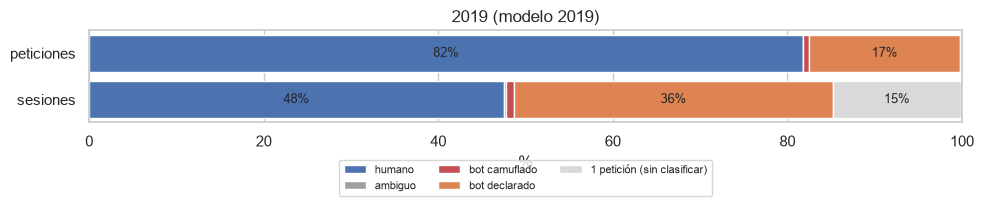

,sesiones,peticiones,% sesiones,% peticiones
categoria,,,,
humano,11667,1265899,47.5,81.8
ambiguo,80,355,0.3,0.0
bot camuflado,229,10645,0.9,0.7
bot declarado,8984,267739,36.5,17.3
1 petición (sin clasificar),3624,3624,14.7,0.2


In [34]:
CATEGORIAS = ['humano', 'ambiguo', 'bot camuflado', 'bot declarado', '1 petición (sin clasificar)']
COLORES = dict(zip(CATEGORIAS, ['#4C72B0', '#A0A0A0', '#C44E52', '#DD8452', '#D9D9D9']))

def entrenar_modelo(ses, k):
    """Entrena k-means sobre las sesiones (ya filtradas) con ≥ 2 peticiones y nombra los clústeres."""
    datos = ses[ses['n_peticiones'] > 1]
    esc = StandardScaler().fit(matriz(datos))
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEMILLA).fit(esc.transform(matriz(datos)))
    _, nombres = nombrar_clusters(datos, km.labels_)
    return {'escalador': esc, 'kmeans': km, 'nombres': nombres}

def clasificar_sesiones(ses, modelo, solo_escritorio=True):
    ses = ses.copy()
    ses['tipo_ua'] = ses['user_agent'].map(etiqueta_ua)
    if solo_escritorio:
        movil = es_movil(ses)
        print(f'Sesiones móviles excluidas: {movil.sum():,} ({movil.mean():.1%})')
        ses = ses[~movil].copy()
    validas = ses['n_peticiones'] > 1
    ses['cluster'] = -1
    ses.loc[validas, 'cluster'] = modelo['kmeans'].predict(modelo['escalador'].transform(matriz(ses[validas])))
    ses['grupo'] = ses['cluster'].map(lambda c: modelo['nombres'].get(c, ('—', '—'))[0])
    tipo = ses['cluster'].map(lambda c: modelo['nombres'].get(c, ('—', '—'))[1])
    ses['categoria'] = np.select(
        [ses['tipo_ua'] == 'bot_declarado', ~validas, tipo == 'automatizado', tipo == 'humano'],
        ['bot declarado', '1 petición (sin clasificar)', 'bot camuflado', 'humano'],
        default='ambiguo')
    return ses

def analizar_log(ruta, modelo, n_lineas=None, horas=None, titulo=None, dibujar=True, devolver_sesiones=False):
    """Estima qué parte del tráfico de un log es humana y qué parte automatizada."""
    log = crear_sesiones(cargar_log(ruta, n_lineas=n_lineas, horas=horas))
    ses = clasificar_sesiones(calcular_variables(log), modelo)
    res = pd.DataFrame({
        'sesiones': ses['categoria'].value_counts(),
        'peticiones': ses.groupby('categoria')['n_peticiones'].sum()}).reindex(CATEGORIAS).fillna(0).astype(int)
    res['% sesiones'] = (100 * res['sesiones'] / res['sesiones'].sum()).round(1)
    res['% peticiones'] = (100 * res['peticiones'] / res['peticiones'].sum()).round(1)
    if dibujar:
        fig, ax = plt.subplots(figsize=(10, 2.6))
        izq = np.zeros(2)
        for cat in CATEGORIAS:
            v = res.loc[cat, ['% sesiones', '% peticiones']].values.astype(float)
            ax.barh(['sesiones', 'peticiones'], v, left=izq, color=COLORES[cat], label=cat)
            for i, x in enumerate(v):
                if x >= 4: ax.text(izq[i] + x / 2, i, f'{x:.0f}%', ha='center', va='center', fontsize=9)
            izq += v
        ax.set(xlim=(0, 100), xlabel='%', title=titulo or ruta)
        ax.legend(ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.35), loc='upper center')
        plt.tight_layout()
        if titulo: plt.savefig(f'figuras/analizar_{re.sub(r"\W+", "_", titulo)}.png', dpi=150, bbox_inches='tight')
        plt.show()
    return (res, ses) if devolver_sesiones else res

modelo19 = {'escalador': escalador19, 'kmeans': km19, 'nombres': nombres19}
res19 = analizar_log(RUTA_2019, modelo19, horas=24, titulo='2019 (modelo 2019)')
res19

**// Comentario:** Aplicada al propio log de 2019, la herramienta estima que el tráfico de ordenador es sobre todo humano: un 47,5 % de las sesiones y un 81,8 % de las peticiones. Los bots declarados son el 36,5 % de las sesiones pero solo el 17,3 % de las peticiones, porque en general sus sesiones son breves (crawlers lentos que piden una página cada varios minutos). Los bots camuflados son una fracción pequeña: el 0,9 % de las sesiones y el 0,7 % de las peticiones. Las sesiones de una sola petición, que quedan sin clasificar, son el 14,7 % de las sesiones y apenas el 0,2 % de las peticiones, así que excluirlas del clustering cuesta poco en esta web. Como las proporciones cambian tanto según se midan en sesiones o en peticiones, la herramienta da siempre las dos cifras.

El modelo entrenado (escalador, k-means, nombres de los grupos y variables usadas) se guarda en disco junto con el resumen de 2019, para poder aplicarlo a otros logs sin volver a entrenar.

In [35]:
import pickle
modelo19_guardado = {**modelo19, 'variables': VARIABLES, 'k': K19, 'resumen_2019': res19}
with open('modelos/modelo_2019.pkl', 'wb') as f:
    pickle.dump(modelo19_guardado, f)
print('Modelo guardado en modelos/modelo_2019.pkl')

Modelo guardado en modelos/modelo_2019.pkl


## 7. Conclusiones

En el tráfico de ordenador, buena parte del tráfico automatizado puede distinguirse solo por el comportamiento de las sesiones, sin usar etiquetas durante el aprendizaje.

Analizar un día completo (2,3 millones de peticiones y 16 507 sesiones de ordenador para el clustering) permite ver el ciclo diario entero: el ordenador domina en horario laboral, el móvil por la tarde y la noche, y los bots mantienen un ritmo constante las 24 horas. Limitar el estudio al ordenador evita mezclar patrones propios de los móviles, como las peticiones automáticas de iconos, y centra el análisis en el perfil que suelen imitar los bots camuflados.

De las once variables candidatas se eliminaron dos, `duracion_s` y `pet_por_min`, porque se reconstruyen casi exactamente a partir de otras ($R^2 > 0,97$). El modelo resultante, con nueve variables, es más sencillo y da grupos estables. k-means con k = 7 encuentra grupos interpretables (navegación humana, visitas cortas, crawlers lentos, crawlers que piden robots.txt, monitorización y acceso directo), y DBSCAN y el clustering aglomerativo confirman la separación principal; el aglomerativo coincide con k-means con un ARI de 0,84.

Al reducir los grupos a automatizado frente a humano, el ARI con la etiqueta aproximada es de 0,744: el 81,5 % de los bots declarados caen en grupos automatizados, frente al 1,9 % de las sesiones de navegador. El método detecta además 229 sesiones con *user-agent* de navegador de escritorio y comportamiento de bot. Entre ellas hay un navegador automatizado que lee `robots.txt` y hace una petición cada medio segundo, y otra sesión que se hace pasar por Internet Explorer 5.

La función `analizar_log` resume cualquier log en cinco categorías. En este log, el peso de cada tipo de tráfico cambia mucho según se mida en sesiones o en peticiones: los bots declarados son el 36,5 % de las sesiones de ordenador pero solo el 17,3 % de las peticiones.

### Limitaciones

Las etiquetas de validación son aproximadas, porque un *user-agent* de navegador no garantiza que detrás haya una persona. Al restringir el estudio al ordenador quedan fuera los bots que se hacen pasar por móviles. La elección de k no es unívoca: k = 4 obtiene mejores índices internos, aunque mezcla visitas humanas con *crawlers*. Las sesiones de una sola petición quedan sin clasificar. Y como el log de 2019 es anterior a la expansión de los *crawlers* y agentes de IA, su comportamiento no se ha podido estudiar.

### Posibles mejoras

Queda por comprobar si el modelo generaliza a tráfico más reciente y a otros tipos de web. También podrían clasificarse las sesiones de una petición con reglas sobre la propia URL, verificarse los bots declarados con sus rangos de IP publicados e incorporarse variables temporales, como la hora del día, o de navegación, como la secuencia de páginas.

## Referencias

- Zaker, F. (2019). *Online Shopping Store – Web Server Logs*. Harvard Dataverse, V1. https://doi.org/10.7910/DVN/3QBYB5 (copia pública en Kaggle: https://www.kaggle.com/datasets/eliasdabbas/web-server-access-logs).
- Van Boxem et al. (2026). *Shy Guys: A Light-Weight Approach to Detecting Robots on Websites*. arXiv:2603.28546.
- *What Does It Take to Detect an AI Agent? Minimal Feature Sets for Behavioral Detection under Browser Automation* (2026). arXiv:2607.26935.
- *In-Application Defense Against Evasive Web Scans through Behavioral Analysis* (2024). arXiv:2412.07005.
- din0s, *ml-for-bot-detection* (detección supervisada sobre el dataset de Zaker). https://github.com/din0s/ml-for-bot-detection
- Documentación de scikit-learn sobre clustering y su evaluación. https://scikit-learn.org/stable/modules/clustering.html
- Formato *combined* de Apache. https://httpd.apache.org/docs/current/logs.html#combined